In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
CM = "..//data//21_cmapss_fd001_sample.csv"
df = pd.read_csv(CM)
sensors = ["s_2", "s_3", "s_4", "s_7", "s_11"]

In [3]:
# ── [개념] 상관행렬·강한 상관쌍·정상 범위 (엔진1) ───────────────────────────
e1 = df[df["unit_nr"] == 1].reset_index(drop=True)

In [4]:
corr1 = e1[sensors].corr()

In [5]:
corr1

,s_2,s_3,s_4,s_7,s_11
s_2,1.000000,0.949652,0.985629,-0.934855,0.813992
s_3,0.949652,1.000000,0.973544,-0.956611,0.837902
s_4,0.985629,0.973544,1.000000,-0.958716,0.827222
s_7,-0.934855,-0.956611,-0.958716,1.000000,-0.825653
s_11,0.813992,0.837902,0.827222,-0.825653,1.000000


In [6]:
ma = e1["s_3"].rolling(20).mean()

In [7]:
print("변화점 후보 주기:", int(e1["time_cycles"].iloc[ma.diff().abs().idxmax()]))  # 187

변화점 후보 주기: 187


In [8]:
s1 = e1["s_3"]

In [9]:
s1

0      1585.21
1      1585.55
2      1584.72
3      1585.94
4      1585.72
        ...   
187    1606.39
188    1608.47
189    1605.65
190    1606.83
191    1609.83
Name: s_3, Length: 192, dtype: float64

In [10]:
(s1 > s1.mean() + 2 * s1.std()) | (s1 < s1.mean() - 2 * s1.std())

0      False
1      False
2      False
3      False
4      False
       ...  
187    False
188    False
189    False
190    False
191     True
Name: s_3, Length: 192, dtype: bool

In [16]:
(s1 > s1.mean() + 2 * s1.std()) | (s1 < s1.mean() - 2 * s1.std()).sum()

0      False
1      False
2      False
3      False
4      False
       ...  
187    False
188    False
189    False
190    False
191     True
Name: s_3, Length: 192, dtype: bool

In [18]:
mask=(s1 > s1.mean() + 2 * s1.std()) | (s1 < s1.mean() - 2 * s1.std()).sum()

In [19]:
s1[mask]

179    1609.64
186    1610.44
191    1609.83
Name: s_3, dtype: float64

In [21]:
#[실습 1] 상관관계 heatmap 해석하기 (엔진2) ────────────────────────────── 4시 20분

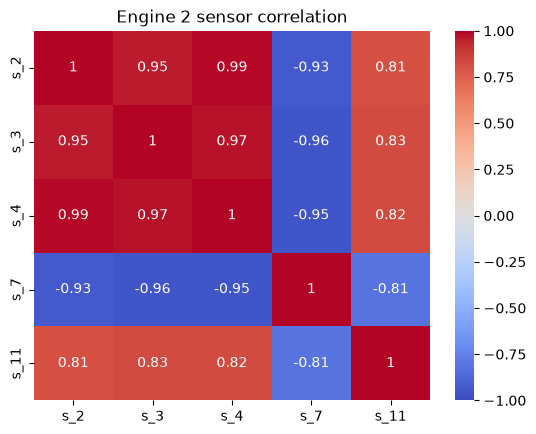

In [22]:
e2 = df[df["unit_nr"] == 2].reset_index(drop=True)
sns.heatmap(e2[sensors].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Engine 2 sensor correlation")
plt.show()

In [25]:
# 실습 2 4시 35분까지

In [26]:
#for i in []:
#    for j in []:
#        print(i,j)

In [27]:
# ── [실습 2] 강하게 연동된 센서 묶음 찾기 ───────────────────────────────────
corr = e2[sensors].corr()
for i in range(len(sensors)):
    for j in range(i + 1, len(sensors)):
        c = corr.iloc[i, j]
        if abs(c) >= 0.9:
            print(
                sensors[i], "-", sensors[j], ":", round(c, 2)
            )  # s_2-s_4 0.99, s_3-s_4 0.97, s_3-s_7 -0.96 ...

s_2 - s_3 : 0.95
s_2 - s_4 : 0.99
s_2 - s_7 : -0.93
s_3 - s_4 : 0.97
s_3 - s_7 : -0.96
s_4 - s_7 : -0.95


In [28]:
e2[sensors].corr()

,s_2,s_3,s_4,s_7,s_11
s_2,1.000000,0.953678,0.985691,-0.932400,0.810446
s_3,0.953678,1.000000,0.974848,-0.956688,0.827375
s_4,0.985691,0.974848,1.000000,-0.953426,0.822796
s_7,-0.932400,-0.956688,-0.953426,1.000000,-0.814919
s_11,0.810446,0.827375,0.822796,-0.814919,1.000000


In [29]:
e2[sensors].corr().values

array([[ 1.        ,  0.95367797,  0.98569067, -0.93240005,  0.81044584],
       [ 0.95367797,  1.        ,  0.97484812, -0.95668756,  0.82737532],
       [ 0.98569067,  0.97484812,  1.        , -0.95342609,  0.82279633],
       [-0.93240005, -0.95668756, -0.95342609,  1.        , -0.81491889],
       [ 0.81044584,  0.82737532,  0.82279633, -0.81491889,  1.        ]])

In [ ]:
e2[sensors].corr().values

In [32]:
abs(e2[sensors].corr().values) >= 0.9

array([[ True,  True,  True,  True, False],
       [ True,  True,  True,  True, False],
       [ True,  True,  True,  True, False],
       [ True,  True,  True,  True, False],
       [False, False, False, False,  True]])

In [33]:
cor_val = abs(e2[sensors].corr().values)

In [34]:
cor_val[abs(e2[sensors].corr().values) >= 0.9]

array([1.        , 0.95367797, 0.98569067, 0.93240005, 0.95367797,
       1.        , 0.97484812, 0.95668756, 0.98569067, 0.97484812,
       1.        , 0.95342609, 0.93240005, 0.95668756, 0.95342609,
       1.        , 1.        ])

In [36]:
import numpy as np

In [37]:
help(np.triu)

Help on method descriptor triu in module numpy:

triu(m, k=0)
    Upper triangle of an array.

    Return a copy of an array with the elements below the `k`-th diagonal
    zeroed. For arrays with ``ndim`` exceeding 2, `triu` will apply to the
    final two axes.

    Please refer to the documentation for `tril` for further details.

    See Also
    --------
    tril : lower triangle of an array

    Examples
    --------
    >>> import numpy as np
    >>> np.triu([[1,2,3],[4,5,6],[7,8,9],[10,11,12]], -1)
    array([[ 1,  2,  3],
           [ 4,  5,  6],
           [ 0,  8,  9],
           [ 0,  0, 12]])

    >>> np.triu(np.arange(3*4*5).reshape(3, 4, 5))
    array([[[ 0,  1,  2,  3,  4],
            [ 0,  6,  7,  8,  9],
            [ 0,  0, 12, 13, 14],
            [ 0,  0,  0, 18, 19]],
           [[20, 21, 22, 23, 24],
            [ 0, 26, 27, 28, 29],
            [ 0,  0, 32, 33, 34],
            [ 0,  0,  0, 38, 39]],
           [[40, 41, 42, 43, 44],
            [ 0, 46, 47, 48

In [39]:
np.ones((3,4))

array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]])

In [40]:
corr

,s_2,s_3,s_4,s_7,s_11
s_2,1.000000,0.953678,0.985691,-0.932400,0.810446
s_3,0.953678,1.000000,0.974848,-0.956688,0.827375
s_4,0.985691,0.974848,1.000000,-0.953426,0.822796
s_7,-0.932400,-0.956688,-0.953426,1.000000,-0.814919
s_11,0.810446,0.827375,0.822796,-0.814919,1.000000


In [41]:
np.ones(corr.shape)

array([[1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1.]])

In [42]:
np.ones(corr.shape, dtype=bool)

array([[ True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True],
       [ True,  True,  True,  True,  True]])

In [44]:
np.triu(np.ones(corr.shape, dtype=bool), k=1)

array([[False,  True,  True,  True,  True],
       [False, False,  True,  True,  True],
       [False, False, False,  True,  True],
       [False, False, False, False,  True],
       [False, False, False, False, False]])

In [45]:
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

In [46]:
# 상관계수 절댓값이 0.9 이상인 쌍만 추출
strong = upper.where(upper.abs() >= 0.9).stack()

In [47]:
strong

s_2   s_2          NaN
      s_3     0.953678
      s_4     0.985691
      s_7    -0.932400
      s_11         NaN
s_3   s_2          NaN
      s_3          NaN
      s_4     0.974848
      s_7    -0.956688
      s_11         NaN
s_4   s_2          NaN
      s_3          NaN
      s_4          NaN
      s_7    -0.953426
      s_11         NaN
s_7   s_2          NaN
      s_3          NaN
      s_4          NaN
      s_7          NaN
      s_11         NaN
s_11  s_2          NaN
      s_3          NaN
      s_4          NaN
      s_7          NaN
      s_11         NaN
dtype: float64

In [48]:
result = strong.rename("corr").reset_index()

In [49]:
result.columns = ["sensor_1", "sensor_2", "corr"]
result["corr"] = result["corr"].round(2)

print(result.to_string(index=False))

sensor_1 sensor_2  corr
     s_2      s_2   NaN
     s_2      s_3  0.95
     s_2      s_4  0.99
     s_2      s_7 -0.93
     s_2     s_11   NaN
     s_3      s_2   NaN
     s_3      s_3   NaN
     s_3      s_4  0.97
     s_3      s_7 -0.96
     s_3     s_11   NaN
     s_4      s_2   NaN
     s_4      s_3   NaN
     s_4      s_4   NaN
     s_4      s_7 -0.95
     s_4     s_11   NaN
     s_7      s_2   NaN
     s_7      s_3   NaN
     s_7      s_4   NaN
     s_7      s_7   NaN
     s_7     s_11   NaN
    s_11      s_2   NaN
    s_11      s_3   NaN
    s_11      s_4   NaN
    s_11      s_7   NaN
    s_11     s_11   NaN


In [50]:
result[result["corr"].notna()]

,sensor_1,sensor_2,corr
1,s_2,s_3,0.95
2,s_2,s_4,0.99
3,s_2,s_7,-0.93
7,s_3,s_4,0.97
8,s_3,s_7,-0.96
13,s_4,s_7,-0.95


In [51]:
# ── [실습 3] 이상 의심 구간 표시하기 ────────────────────────────────────────
std20 = e2["s_3"].rolling(20).std()


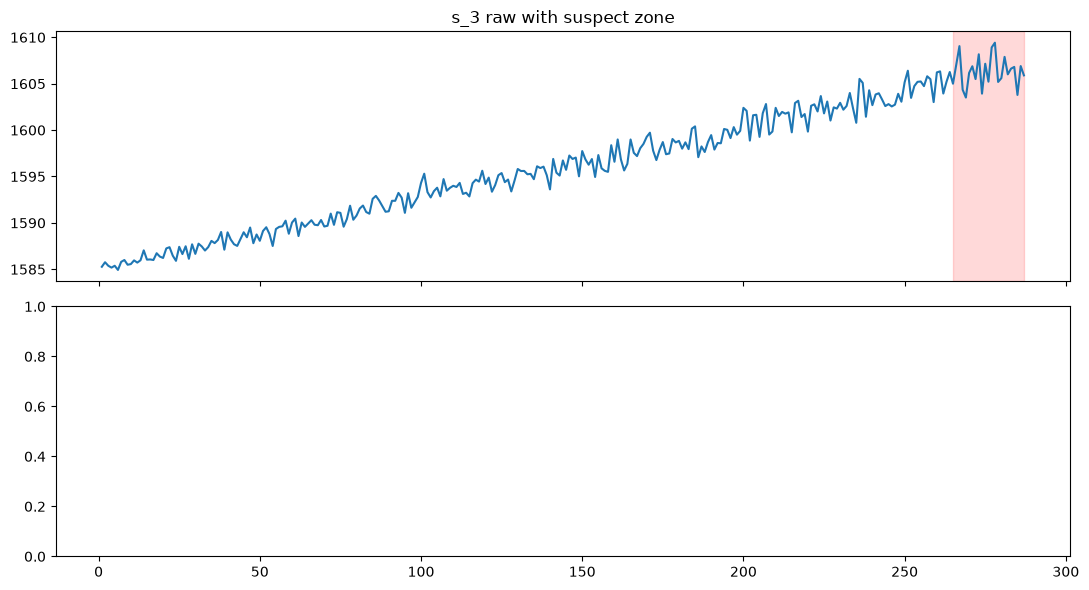

In [52]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2["time_cycles"], e2["s_3"])
ax1.axvspan(265, 287, color="red", alpha=0.15)
ax1.set_title("s_3 raw with suspect zone")
plt.tight_layout()
plt.show()

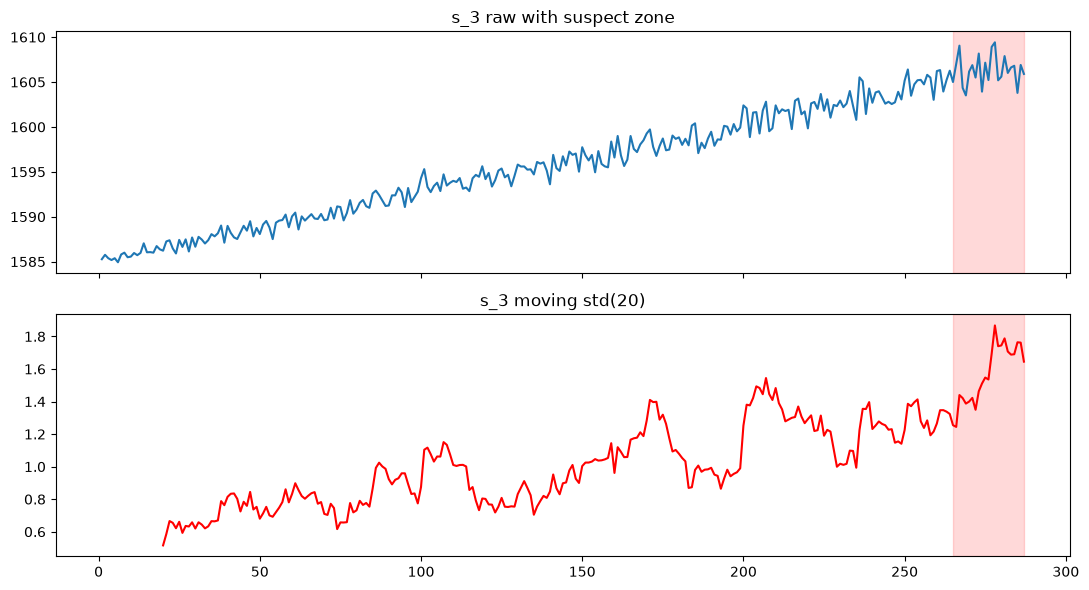

In [53]:
# ── [실습 3] 이상 의심 구간 표시하기 ────────────────────────────────────────
std20 = e2["s_3"].rolling(20).std()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.plot(e2["time_cycles"], e2["s_3"])
ax1.axvspan(265, 287, color="red", alpha=0.15)
ax1.set_title("s_3 raw with suspect zone")
ax2.plot(e2["time_cycles"], std20, color="red")
ax2.axvspan(265, 287, color="red", alpha=0.15)
ax2.set_title("s_3 moving std(20)")
plt.tight_layout()
plt.show()

In [54]:
# ── [실습 4] 정상 범위 벗어난 점 찾기 ───────────────────────────────────────
s = e2["s_3"]

In [55]:
s

0      1585.27
1      1585.76
2      1585.38
3      1585.18
4      1585.38
        ...   
282    1606.62
283    1606.81
284    1603.79
285    1606.90
286    1605.90
Name: s_3, Length: 287, dtype: float64

In [56]:
m, sd = s.mean(), s.std()

In [57]:
lower, upper = m - 2 * sd, m + 2 * sd

In [58]:
print("정상 범위:", round(lower, 2), "~", round(upper, 2))  # 1583.17 ~ 1608.94

정상 범위: 1583.17 ~ 1608.94


In [59]:
out = ((s > upper) | (s < lower)).sum()

In [61]:
((s > upper) | (s < lower))

0      False
1      False
2      False
3      False
4      False
       ...  
282    False
283    False
284    False
285    False
286    False
Name: s_3, Length: 287, dtype: bool

In [ ]:
out = ((s > upper) | (s < lower)).sum()

In [60]:
out

np.int64(2)

In [62]:
#실습 5 5시 40분 까지 3명 발표

In [64]:
# 여러분이 수집한 데이터로 해보세요